# 3. Finding the sung notes

Before anything can be corrected, the app must answer: **which notes did the singer sing, when, and how
far off are they?** That takes two steps:

1. **Pitch tracking**: estimate the fundamental frequency $f_0$ every ~12 ms (a time series).
2. **Note segmentation**: cut that continuous line into discrete notes, each with a start, an end and
   one representative pitch.

All of it lives in `pitch.detect_notes`. Throughout, we use a synthetic voice whose true pitches we know.

In [1]:
%matplotlib inline
import warnings; warnings.filterwarnings("ignore")  # hide library chatter (progress bars etc.)
import numpy as np
import matplotlib.pyplot as plt
import librosa
from nbtools import *   # synthetic sounds, play(), plots (see nbtools.py)
plt.rcParams["figure.dpi"] = 90

## 3.1 The idea behind pitch tracking: a sound that repeats

A sung note is (almost) periodic: the waveform repeats every $1/f_0$ seconds. One way to find the period is
**autocorrelation**: correlate a short frame with shifted copies of itself. At a shift equal to the period,
the frame lines up with itself and the correlation peaks.

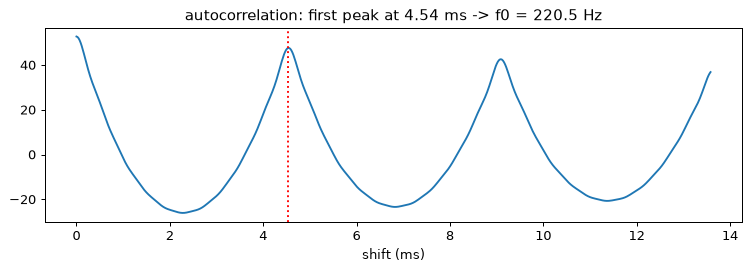

In [2]:
voice = voice_like([57], note_s=1.0, vibrato_cents=0)    # A3 = 220 Hz, no vibrato
frame = voice[0, 20000:20000 + 2048]
ac = np.correlate(frame, frame, mode="full")[len(frame) - 1:]
lags_ms = np.arange(len(ac)) / SR * 1000
peak = np.argmax(ac[50:]) + 50                               # skip the trivial peak at lag 0
fig, ax = plt.subplots(figsize=(10, 2.8))
ax.plot(lags_ms[:600], ac[:600]); ax.axvline(lags_ms[peak], color="r", ls=":")
ax.set_xlabel("shift (ms)"); ax.set_title(f"autocorrelation: first peak at {lags_ms[peak]:.2f} ms -> f0 = {SR / peak:.1f} Hz")
plt.show()

Plain autocorrelation makes **octave errors** (a peak at twice the period also scores well) and does not say
whether a frame is sung at all. Two refinements, both in librosa:

* **YIN** (2002) uses a normalised *difference* function instead of correlation and picks the first dip below a
  threshold, which removes most octave errors.
* **pYIN** (probabilistic YIN, 2014) keeps *several* candidate pitches per frame with probabilities, plus a
  "not voiced" option, and then runs a **hidden Markov model** (Viterbi again) to choose a smooth path
  through them. Pitch does not jump randomly between frames, so the HMM's transition model prefers small
  changes, the same idea as smoothing labels with an HMM in sequence ML.

The app runs pYIN at 22,050 Hz with a hop of 256 samples (one estimate every 11.6 ms), between 65 and
1050 Hz (the range of a singing voice).

## 3.2 Tracking a melody

A four-note melody, sung with vibrato, with **known errors**: A3 in tune, C4 30 cents sharp, D4 in tune,
E4 40 cents sharp (64.4).

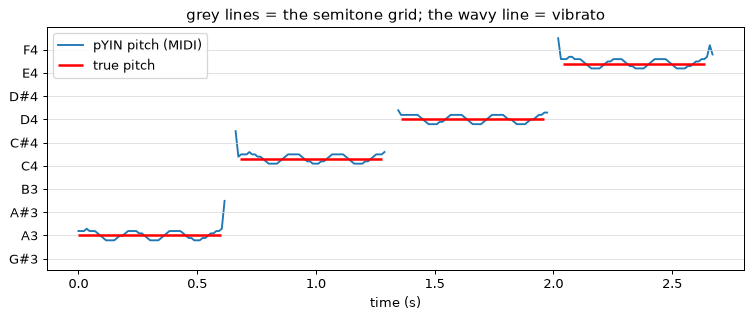

221 of 235 frames voiced (the gaps between notes are not)


In [3]:
truth = [57.0, 60.3, 62.0, 64.4]
melody = voice_like(truth, note_s=0.6, vibrato_cents=25)
play(melody)

from songpolish.pitch import ANALYSIS_SR, HOP, FMIN, FMAX
y = librosa.resample(melody[0], orig_sr=SR, target_sr=ANALYSIS_SR)
f0, voiced, prob = librosa.pyin(y, fmin=FMIN, fmax=FMAX, sr=ANALYSIS_SR, frame_length=1024, hop_length=HOP)
t = np.arange(len(f0)) * HOP / ANALYSIS_SR
midi_track = librosa.hz_to_midi(f0)

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(t, midi_track, label="pYIN pitch (MIDI)")
for m in range(56, 66): ax.axhline(m, color="0.85", lw=0.6)
for i, m in enumerate(truth): ax.hlines(m, i * 0.68, i * 0.68 + 0.6, color="r", lw=2, label="true pitch" if i == 0 else None)
ax.set_yticks(range(56, 66)); ax.set_yticklabels([note_name(m) for m in range(56, 66)])
ax.set_xlabel("time (s)"); ax.legend(); ax.set_title("grey lines = the semitone grid; the wavy line = vibrato")
plt.show()
print(f"{voiced.sum()} of {len(voiced)} frames voiced (the gaps between notes are not)")

## 3.3 From a pitch line to notes

The track is continuous and wavy. To get notes, `detect_notes`:

1. converts Hz to MIDI and subtracts the **guitar's tuning offset** (notebook 2), so integers are the guitar's notes,
2. takes each **voiced run** (consecutive voiced frames),
3. smooths it with a **median filter** over 150 ms (robust to vibrato) and **splits** it wherever the nearest
   semitone of the smoothed line changes,
4. **merges** neighbouring pieces whose average pitches are less than 0.6 semitones apart (see 3.4),
5. keeps only **stable** pieces: at least 80 ms long (shorter ones are transitions) and with a standard
   deviation of at most 0.7 semitones (otherwise it is a glide or slide, not a note),
6. gives each note one pitch: the **trimmed mean** of its frames (see 3.5),
7. drops **phantom notes** (see 3.6).

In [4]:
from songpolish.pitch import detect_notes
notes = detect_notes(melody)
print(" note | start-end (s) | measured | true  | error vs truth")
for n, m in zip(notes, truth):
    print(f" {note_name(n.pitch):4s} | {n.start/SR:.2f}-{n.end/SR:.2f}   | {n.pitch:7.2f}  | {m:5.2f} | {100*(n.pitch-m):+5.1f} cents")

 note | start-end (s) | measured | true  | error vs truth
 A3   | 0.00-0.61   |   57.03  | 57.00 |  +3.3 cents
 C4   | 0.68-1.29   |   60.33  | 60.30 |  +3.3 cents
 D4   | 1.34-1.98   |   62.04  | 62.00 |  +4.1 cents
 E4   | 2.01-2.68   |   64.45  | 64.40 |  +4.6 cents


The measured pitches are within a few cents of the truth, even with ±25 cents of vibrato.

## 3.4 Why pieces are merged: vibrato around a half-semitone

Imagine a note sung at 60.5, exactly between C and C#, with vibrato. Its pitch line crosses the
half-semitone boundary five times a second, so "split where the nearest semitone changes" would chop one
sung note into many short C and C# pieces, and each piece would be pulled in the *opposite* direction.
Real note changes are at least about a semitone apart, so pieces closer than 0.6 semitones are re-joined.

In [5]:
wobbly = voice_like([60.5], note_s=1.2, vibrato_cents=30)
y = librosa.resample(wobbly[0], orig_sr=SR, target_sr=ANALYSIS_SR)
f0, v, _ = librosa.pyin(y, fmin=FMIN, fmax=FMAX, sr=ANALYSIS_SR, frame_length=1024, hop_length=HOP)
m = librosa.hz_to_midi(f0[v])
changes = int(np.sum(np.diff(np.round(m)) != 0))
print(f"the nearest semitone flips {changes} times inside one sung note")
print("notes found by detect_notes:", [(round(n.pitch, 2), round((n.end - n.start) / SR, 2)) for n in detect_notes(wobbly)])

the nearest semitone flips 13 times inside one sung note


notes found by detect_notes: [(60.53, 1.21)]


## 3.5 One number per note: why a *trimmed mean*

A note with vibrato is heard at roughly its **average** pitch. Which average?

* The **median** is robust, but pYIN quantises its output to 10-cent steps, so the median is stuck on that
  grid (it can be up to 5 cents off).
* The plain **mean** averages across the grid (vibrato "dithers" the quantisation), so it is accurate, but
  sensitive to the **scoop** at the start of a note (singers often slide into it from below).
* The **trimmed mean** (drop the lowest and highest 15% of frames, then average) is both: accurate and
  robust to scoops. It's a standard robust statistic.

Below: a note at 62.37 (D4 + 37 cents) that starts with a scoop from a semitone below.

In [6]:
from scipy.stats import trim_mean
note = voice_like([62.37], note_s=0.8, vibrato_cents=25)
scoop_len = int(0.12 * SR)                      # replace the first 120 ms with a slide up from 61.4
t = np.arange(scoop_len) / SR
f = midi_to_hz(61.4) * 2 ** ((np.linspace(0, 0.97, scoop_len)) / 12)
note[0, :scoop_len] = 0.3 * sum((0.6 / k) * np.sin(k * 2 * np.pi * np.cumsum(f) / SR) for k in range(1, 12)) * np.minimum(1, t / 0.04)
y = librosa.resample(note[0], orig_sr=SR, target_sr=ANALYSIS_SR)
f0, v, _ = librosa.pyin(y, fmin=FMIN, fmax=FMAX, sr=ANALYSIS_SR, frame_length=1024, hop_length=HOP)
frames = librosa.hz_to_midi(f0[v])
print(f"true pitch of the held part: 62.37")
print(f"median:       {np.median(frames):.3f}   (stuck on pYIN's 10-cent grid)")
print(f"mean:         {np.mean(frames):.3f}   (pulled down by the scoop)")
print(f"trimmed mean: {trim_mean(frames, 0.15):.3f}")

true pitch of the held part: 62.37


median:       62.292   (stuck on pYIN's 10-cent grid)
mean:         62.317   (pulled down by the scoop)
trimmed mean: 62.347


## 3.6 Phantom notes: when the "voice" is actually faint guitar

On a single recording, the voice is first separated from the guitar by a neural network (notebook 6). Its
"voice" output is never perfectly empty where nobody sings: faint guitar remains, 40–90 dB below the
singing. pYIN happily finds pitches in it. On the real song **a third of all detected notes were such
phantoms**, and correcting them caused audible artefacts.

The fix is a relative level threshold: a note more than **30 dB below the loud notes** (90th percentile
of note levels) is dropped. On the real song, real notes were all within 20 dB and phantoms 40–90 dB
below, so the gap is wide. It must be *relative*: a quiet singer is quiet everywhere.

In [7]:
from songpolish.pitch import PHANTOM_DB
sung = voice_like([60, 62])
bleed = 10 ** (-50 / 20) * voice_like([64, 65, 67], seed=3)     # the same kind of signal, 50 dB weaker
stem = np.concatenate([sung, bleed, sung], axis=1)
print("notes in the faint part alone (nothing louder to compare with):", [note_name(n.pitch) for n in detect_notes(bleed)])
print("notes in the whole stem:", [note_name(n.pitch) for n in detect_notes(stem)], f"(phantoms more than {PHANTOM_DB:.0f} dB down are dropped)")

notes in the faint part alone (nothing louder to compare with): ['E4', 'F4', 'G4']


notes in the whole stem: ['C4', 'D4', 'C4', 'D4'] (phantoms more than 30 dB down are dropped)


## Summary

* **pYIN** estimates $f_0$ every 11.6 ms with a probabilistic YIN + HMM smoothing, and flags unvoiced frames.
* `detect_notes` turns the pitch line into notes: split where the smoothed nearest semitone changes, re-merge
  vibrato-split pieces (< 0.6 st apart), keep stable pieces (≥ 80 ms, std ≤ 0.7 st).
* Each note's pitch is a **trimmed mean** of its frames: accurate under pYIN's quantisation and robust to scoops.
* Notes 30 dB below the loud notes are **phantoms** (bleed in the separated voice) and are ignored.

Each note is now a `SungNote(start, end, pitch, frames)`. Next: **notebook 4**, deciding where each
note *should* be.